# Phase 12: is it the features?

**Owner:** Rotana · **Writes to:** `data/processed/12_feature_check/`

**Question.** The tuned SVM reaches only 0.26 validation macro F1 (floor 0.187) and still overfits. The team's assumption: the features (HOG on a 64 × 64 grayscale square + 5 simple measures, cut to 60 PCA components) don't carry enough to tell the classes apart, so no model or tuning can do much better. This notebook tests that assumption instead of assuming it.

| Check | What we change | If the features are the limit |
|---|---|---|
| 1. PCA sweep | how much of the features the model sees: 20, 60, 120, 300 components, or all 1,769 | the score stays flat as components go up |
| 2. Other models | the model, on the same 60 components | very different models all land close together |
| 3. Learning curve | the number of training squares: 2,500 → 46,408 | the score stops rising long before 46k |
| 4. The labels | nothing; we look at what a "damage" square really contains | (rules out the other suspect: weak or noisy labels) |

Same rows as Phase 11 (46,408 balanced training squares, 36,000 validation squares), same `StandardScaler` → `PCA` → model pipeline and the same `class_weight="balanced"` where a model has it. The test set is not loaded. Nothing is tuned here: each model runs with standard settings, because we compare trends, not best scores.


## 1. Setup

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score
from sklearn.neighbors import KNeighborsClassifier

sys.path.insert(0, str(Path.cwd().parents[1]))
from ml import config
from ml.training import floor_macro_f1, load_data, make_pipeline, output_dir

SEED = config.SEED
OUT = output_dir("12_feature_check")
LABELS = list(range(len(config.CLASSES)))
D40 = config.CLASS_TO_ID["D40"]
JOBS = 4                         # leave cores free for other runs

X_tr, y_tr, groups_tr, X_va, y_va = load_data()
X_tr, X_va = X_tr.astype(np.float32), X_va.astype(np.float32)   # half the memory, same results
FLOOR = floor_macro_f1(y_va)
print("train", X_tr.shape, "| val", X_va.shape, f"| floor {FLOOR:.3f}")

rows = []


def score(check, model, setting, pipe, X=None, y=None):
    """Fit on training squares, score train + validation macro F1 and pothole recall, log one row."""
    X, y = (X_tr, y_tr) if X is None else (X, y)
    t = time.perf_counter()
    pipe.fit(X, y)
    fit_s = time.perf_counter() - t
    pred_va = pipe.predict(X_va)
    row = {"check": check, "model": model, "setting": setting, "n_train": len(y),
           "train F1": round(f1_score(y, pipe.predict(X), labels=LABELS, average="macro", zero_division=0), 4),
           "val F1": round(f1_score(y_va, pred_va, labels=LABELS, average="macro", zero_division=0), 4),
           "D40 recall": round(recall_score(y_va, pred_va, labels=[D40], average=None, zero_division=0)[0], 4),
           "fit s": round(fit_s, 1)}
    rows.append(row)
    pd.DataFrame(rows).to_csv(OUT / "feature_check_log.csv", index=False)
    print(f"{model:14s} {setting:>12s} n={len(y):>6,}: val F1 {row['val F1']:.4f} | train F1 {row['train F1']:.4f} "
          f"| D40 recall {row['D40 recall']:.3f} | fit {fit_s:.0f} s")
    return pipe


def softmax():
    return LogisticRegression(max_iter=2000, class_weight="balanced")


def forest():
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                                  n_jobs=JOBS, random_state=SEED)


train (46408, 1769) | val (36000, 1769) | floor 0.187


## 2. Check 1: give the model more of the same features (PCA sweep)

60 components keep about half of the variance. If PCA throws away what separates the classes, more components should score clearly higher. Two models: softmax (straight boundaries) and a random forest (curved ones).


softmax                  20 n=46,408: val F1 0.2077 | train F1 0.2799 | D40 recall 0.521 | fit 5 s
                         20 components keep 36% of the variance


random forest            20 n=46,408: val F1 0.2696 | train F1 0.9292 | D40 recall 0.109 | fit 36 s


softmax                  60 n=46,408: val F1 0.2094 | train F1 0.2925 | D40 recall 0.508 | fit 103 s
                         60 components keep 50% of the variance


random forest            60 n=46,408: val F1 0.2473 | train F1 0.9603 | D40 recall 0.041 | fit 43 s


softmax                 120 n=46,408: val F1 0.2133 | train F1 0.3023 | D40 recall 0.540 | fit 75 s
                        120 components keep 62% of the variance


random forest           120 n=46,408: val F1 0.2299 | train F1 0.9755 | D40 recall 0.005 | fit 63 s


softmax                 300 n=46,408: val F1 0.2159 | train F1 0.3142 | D40 recall 0.513 | fit 156 s
                        300 components keep 81% of the variance


random forest           300 n=46,408: val F1 0.2280 | train F1 0.9858 | D40 recall 0.000 | fit 104 s


softmax           all 1,769 n=46,408: val F1 0.2194 | train F1 0.3980 | D40 recall 0.361 | fit 1679 s


random forest     all 1,769 n=46,408: val F1 0.2307 | train F1 0.9990 | D40 recall 0.000 | fit 213 s


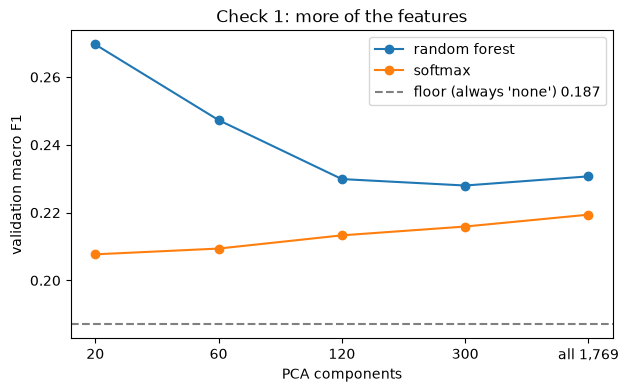

In [2]:
pca_steps = [20, 60, 120, 300, None]          # None = all 1,769 (PCA only rotates)
for n in pca_steps:
    label = "all 1,769" if n is None else str(n)
    p = score("1. PCA sweep", "softmax", label, make_pipeline(softmax(), n_components=n))
    if n is not None:
        print(f"{'':14s} {label:>12s} components keep {p.named_steps['pca'].explained_variance_ratio_.sum():.0%} of the variance")
    score("1. PCA sweep", "random forest", label, make_pipeline(forest(), n_components=n))

sweep = pd.DataFrame([r for r in rows if r["check"] == "1. PCA sweep"])
fig, ax = plt.subplots(figsize=(7, 4))
for m, g in sweep.groupby("model"):
    ax.plot(g["setting"], g["val F1"], marker="o", label=m)
ax.axhline(FLOOR, ls="--", c="grey", label=f"floor (always 'none') {FLOOR:.3f}")
ax.set(xlabel="PCA components", ylabel="validation macro F1", title="Check 1: more of the features")
ax.legend()
fig.savefig(OUT / "check1_pca_sweep.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Check 2: very different models, same 60 components

If the input is the limit, models built on completely different ideas end up close together. The SVM numbers come from `11_2_svm` (section 5 and the best Phase 12 try).


k-NN (k=15)              60 n=46,408: val F1 0.2358 | train F1 0.3283 | D40 recall 0.041 | fit 5 s


boosted trees            60 n=46,408: val F1 0.2352 | train F1 0.4937 | D40 recall 0.416 | fit 6 s
                    model  val F1  train F1  D40 recall
                  softmax  0.2094    0.2925      0.5085
            boosted trees  0.2352    0.4937      0.4165
              k-NN (k=15)  0.2358    0.3283      0.0412
            random forest  0.2473    0.9603      0.0412
           SVM, section 5  0.2571    0.7052      0.2591
SVM, best Phase 12 so far  0.2763    0.7537      0.1186


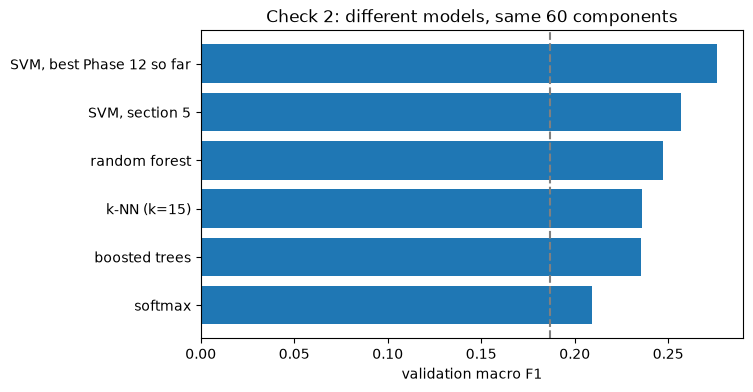

In [3]:
score("2. models", "k-NN (k=15)", "60", make_pipeline(KNeighborsClassifier(n_neighbors=15, n_jobs=JOBS)))
score("2. models", "boosted trees", "60", make_pipeline(
    HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED)))

svm_log = pd.read_csv(config.PROCESSED / "11_2_svm" / "phase12_log.csv")
cols = ["model", "val F1", "train F1", "D40 recall"]
svm_rows = pd.DataFrame([svm_log.iloc[0], svm_log.loc[svm_log["val F1"].idxmax()]])
svm_rows["model"] = ["SVM, section 5", "SVM, best Phase 12 so far"]
models = pd.concat([
    pd.DataFrame([r for r in rows if r["setting"] == "60" and r["check"] != "3. learning curve"])[cols],
    svm_rows[cols],
], ignore_index=True).sort_values("val F1")
print(models.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(models["model"], models["val F1"])
ax.axvline(FLOOR, ls="--", c="grey")
ax.set(xlabel="validation macro F1", title="Check 2: different models, same 60 components")
fig.savefig(OUT / "check2_models.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Check 3: learning curve

Train on more and more squares (random subsets of the 46,408). Still rising at the end: more data would help. Flat early: more data won't, and the features are the ceiling.


softmax                  60 n= 2,500: val F1 0.2033 | train F1 0.3501 | D40 recall 0.392 | fit 0 s


boosted trees            60 n= 2,500: val F1 0.2254 | train F1 1.0000 | D40 recall 0.002 | fit 6 s


softmax                  60 n= 5,000: val F1 0.1987 | train F1 0.3168 | D40 recall 0.383 | fit 1 s


boosted trees            60 n= 5,000: val F1 0.2361 | train F1 0.9970 | D40 recall 0.017 | fit 3 s


softmax                  60 n=10,000: val F1 0.2055 | train F1 0.3019 | D40 recall 0.470 | fit 1 s


boosted trees            60 n=10,000: val F1 0.2523 | train F1 0.9536 | D40 recall 0.111 | fit 4 s


softmax                  60 n=20,000: val F1 0.2033 | train F1 0.2899 | D40 recall 0.501 | fit 2 s


boosted trees            60 n=20,000: val F1 0.2335 | train F1 0.5511 | D40 recall 0.397 | fit 2 s


softmax                  60 n=46,408: val F1 0.2095 | train F1 0.2925 | D40 recall 0.508 | fit 6 s


boosted trees            60 n=46,408: val F1 0.2349 | train F1 0.4714 | D40 recall 0.460 | fit 8 s


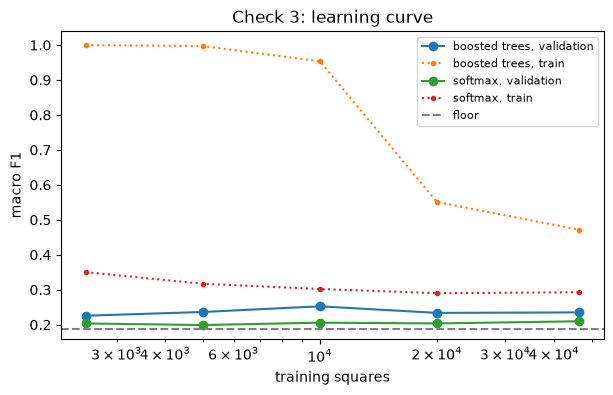

In [4]:
rng = np.random.default_rng(SEED)
order = rng.permutation(len(y_tr))
sizes = [2_500, 5_000, 10_000, 20_000, len(y_tr)]
for n in sizes:
    i = order[:n]
    score("3. learning curve", "softmax", "60", make_pipeline(softmax()), X_tr[i], y_tr[i])
    score("3. learning curve", "boosted trees", "60", make_pipeline(
        HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED)), X_tr[i], y_tr[i])

curve = pd.DataFrame([r for r in rows if r["check"] == "3. learning curve"])
fig, ax = plt.subplots(figsize=(7, 4))
for m, g in curve.groupby("model"):
    ax.plot(g["n_train"], g["val F1"], marker="o", label=f"{m}, validation")
    ax.plot(g["n_train"], g["train F1"], marker=".", ls=":", label=f"{m}, train")
ax.axhline(FLOOR, ls="--", c="grey", label="floor")
ax.set(xscale="log", xlabel="training squares", ylabel="macro F1", title="Check 3: learning curve")
ax.legend(fontsize=8)
fig.savefig(OUT / "check3_learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. Check 4: what does a "damage" square really contain?

A square is labelled with a damage class when one damage box covers at least 10% of it (`LABEL_MIN_OVERLAP`). So a "pothole" square can be 90% plain road. If most damage squares are only lightly covered, the labels themselves are weak, and that limits every model on top of the features.

Coverage = the largest share of the square covered by one box of its own class. Then: does the tuned SVM (section 5) find damage better when the square is well covered?


In [5]:
import joblib
from PIL import Image

meta = np.load(config.PROCESSED / "09_features" / "meta.npz", allow_pickle=True)
patches = pd.read_csv(config.PROCESSED / "06_squares" / "patches.csv").set_index("patch_id")
boxes = pd.read_csv(config.PROCESSED / "06_squares" / "boxes_640x400.csv")
va = pd.DataFrame({"patch_id": meta["patch_id"][meta["split"] == "val"], "y": y_va})
va = va.join(patches[["image_id", "row", "col", "label"]], on="patch_id")
assert (va["label"].map(config.CLASS_TO_ID) == va["y"]).all()

S = config.SQUARE
def coverage(r):
    b = boxes[(boxes["image_id"] == r.image_id) & (boxes["cls"] == r.label)]
    x0, y0 = r.col * S, r.row * S
    w = (np.minimum(b["xmax"], x0 + S) - np.maximum(b["xmin"], x0)).clip(lower=0)
    h = (np.minimum(b["ymax"], y0 + S) - np.maximum(b["ymin"], y0)).clip(lower=0)
    return float((w * h).max() / S**2) if len(b) else np.nan

damage = va[va["label"] != "none"].copy()
boxes = boxes[boxes["image_id"].isin(damage["image_id"])]
damage["coverage"] = [coverage(r) for r in damage.itertuples()]
bins = pd.cut(damage["coverage"], [0, 0.25, 0.5, 0.75, 1.0], include_lowest=True)
print("share of validation damage squares by box coverage:")
print(pd.crosstab(damage["label"], bins, normalize="index").round(2).to_string())

svm = joblib.load(config.PROCESSED / "11_2_svm" / "best_pipeline.joblib")   # section 5 model
t = time.perf_counter()
va["pred"] = svm.predict(X_va)
print(f"\nSVM predictions on validation: {time.perf_counter() - t:.0f} s")
damage["found"] = va.loc[damage.index, "pred"] == damage["y"]
print("\nSVM recall by coverage (share of damage squares of each kind it gets right):")
print(damage.groupby([damage["label"], bins], observed=True)["found"].agg(["mean", "size"]).round(3).unstack().to_string())
damage.to_csv(OUT / "val_damage_coverage.csv")


share of validation damage squares by box coverage:
coverage  (-0.001, 0.25]  (0.25, 0.5]  (0.5, 0.75]  (0.75, 1.0]
label                                                          
D00                 0.32         0.32         0.19         0.16
D10                 0.37         0.48         0.14         0.02
D20                 0.12         0.18         0.19         0.50
D40                 0.34         0.29         0.16         0.21



SVM predictions on validation: 154 s

SVM recall by coverage (share of damage squares of each kind it gets right):
                   mean                                               size                                    
coverage (-0.001, 0.25] (0.25, 0.5] (0.5, 0.75] (0.75, 1.0] (-0.001, 0.25] (0.25, 0.5] (0.5, 0.75] (0.75, 1.0]
label                                                                                                         
D00               0.259       0.297       0.273       0.230            239         239         143         122
D10               0.246       0.312       0.432       0.714            118         154          44           7
D20               0.362       0.466       0.493       0.540            362         537         566        1450
D40               0.214       0.202       0.358       0.333            140         119          67          87


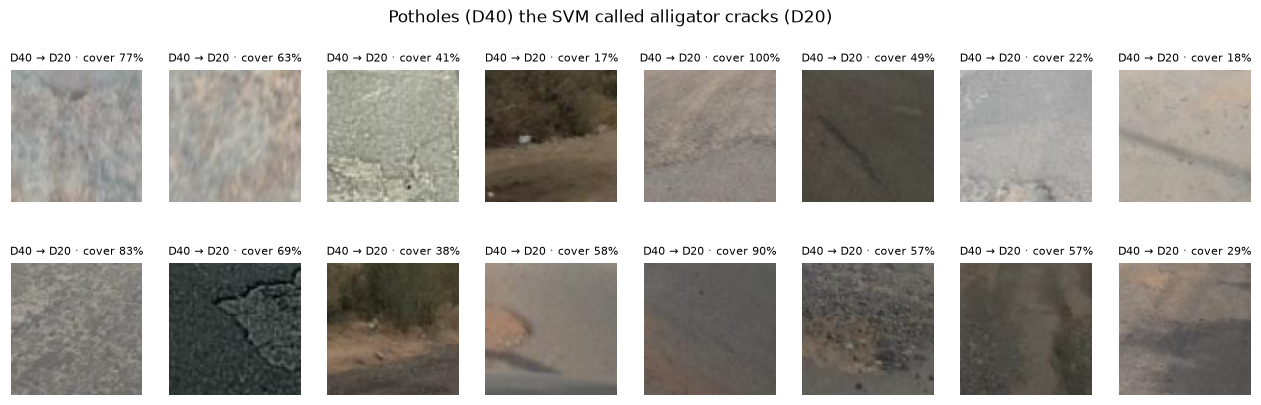

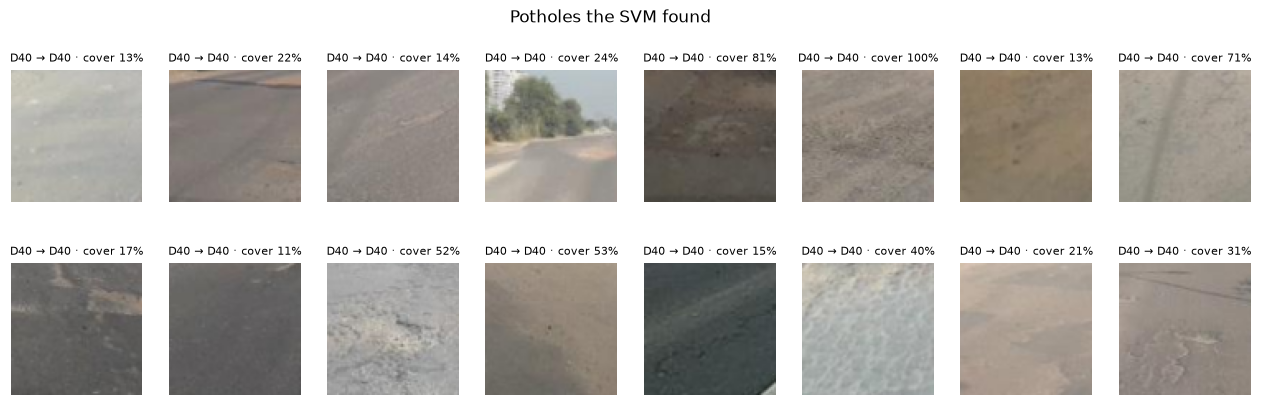

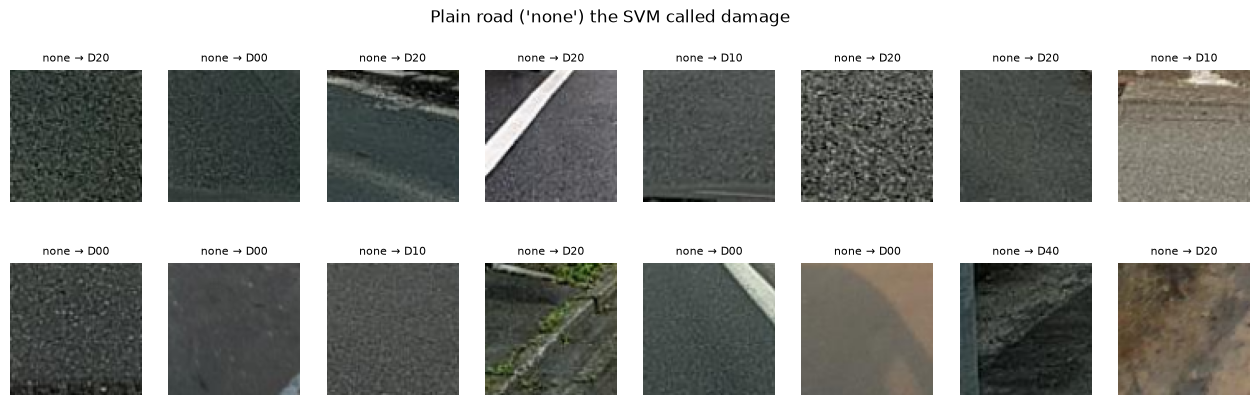

In [6]:
# Look at the mistakes: potholes called alligator cracks, and plain road called damage
def show(df, title, path, n=16):
    pick = df.sample(min(n, len(df)), random_state=SEED)
    fig, axs = plt.subplots(2, 8, figsize=(16, 4.6))
    for ax, r in zip(axs.flat, pick.itertuples()):
        ax.imshow(Image.open(config.PROCESSED / "06_squares" / "patches" / r.label / f"{r.patch_id}.png"))
        cov = f" · cover {r.coverage:.0%}" if hasattr(r, "coverage") and r.coverage == r.coverage else ""
        ax.set_title(f"{r.label} → {config.CLASSES[r.pred]}{cov}", fontsize=8)
    for ax in axs.flat:
        ax.axis("off")
    fig.suptitle(title)
    fig.savefig(OUT / path, dpi=120, bbox_inches="tight")
    plt.show()

damage["pred"] = va.loc[damage.index, "pred"]
show(damage[(damage["label"] == "D40") & (damage["pred"] == config.CLASS_TO_ID["D20"])],
     "Potholes (D40) the SVM called alligator cracks (D20)", "check4_d40_as_d20.png")
show(damage[(damage["label"] == "D40") & damage["found"]], "Potholes the SVM found", "check4_d40_found.png")
none = va[(va["label"] == "none") & (va["pred"] != config.CLASS_TO_ID["none"])]
show(none, "Plain road ('none') the SVM called damage", "check4_none_as_damage.png")


## 6. What the checks say

**Verdict: the features are the main limit, and weak labels add to it.**

| Check | Result | Reading |
|---|---|---|
| 1. PCA sweep | softmax 0.208 (20 comp.) → 0.219 (all 1,769); random forest best at 20 (0.270), worse with more | more of the same features adds almost nothing; the extra components are mostly noise the forest memorises (train F1 0.93 → 1.00) |
| 2. Other models | softmax 0.209, boosted trees 0.235, k-NN 0.236, random forest 0.247, SVM 0.257 → 0.276 tuned | five different methods in one narrow band just above the 0.187 floor; only straight boundaries (softmax) fall clearly lower |
| 3. Learning curve | softmax 0.203 → 0.210, boosted trees 0.225 → 0.235 from 2,500 to 46,408 squares | flat after about 5,000–10,000 squares: more data of this kind won't help |
| 4. Labels | 32–37% of D00, D10 and D40 validation squares are at most 25% covered by their box; 63% of potholes at most 50% | many "damage" squares are mostly plain road |

**Check 4 in more detail.**
- Coverage matters: SVM recall rises with coverage for D10 (0.25 → 0.71), D20 (0.36 → 0.54) and D40 (0.21 → 0.33–0.36). So weak labels cost part of the score.
- But even potholes that fill most of the square are found only about one time in three, so better labels alone would not fix it.

**What the pictures show.**
- The plain road called damage is rough asphalt texture, white lane markings, kerbs, shadows, grass and soil: anything with strong edges. HOG measures edge directions in grayscale. It can't tell a crack from a paint line or coarse aggregate, and without colour it can't see that a line is white paint or that a patch is grass.
- Many potholes called alligator cracks are ravelled or patched areas that look much like D20 at 80 × 80 pixels, and several are blurry or mostly roadside.

**What this means for the next phase.**
1. Tuning the current models further is not worth it: the best SVM (0.276) is near what these features allow.
2. To go clearly higher, change the input:
   - add colour (e.g. colour histograms or HSV statistics) and texture features (e.g. LBP);
   - or, most promising, pretrained CNN features (e.g. ResNet) with a simple model on top.
3. Optionally raise `LABEL_MIN_OVERLAP` (e.g. 0.25) to make the damage labels cleaner. That changes Phases 6–9 for everyone, so it's a team decision.

Outputs: `feature_check_log.csv`, `check1_pca_sweep.png`, `check2_models.png`, `check3_learning_curve.png`, `check4_*.png` and `val_damage_coverage.csv` in `data/processed/12_feature_check/`.
